In [ ]:
# The purpose of this notebook is to try multi output gaussian process model

In [1]:
# import data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)

print()

In [4]:
# Show the 25 original formulas and their three measured targets from df.
formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "Dry Strength Mean",
    "Wet Strength Mean",
]
raw_data_summary = df[formula_cols + measured_target_cols].copy()
raw_data_summary[formula_cols] = raw_data_summary[formula_cols].fillna(0.0)
raw_data_summary[measured_target_cols] = raw_data_summary[measured_target_cols].apply(
    pd.to_numeric, errors="raise"
)

assert len(raw_data_summary) == 25, (
    f"Expected the 25 original samples; found {len(raw_data_summary)}."
)
display(raw_data_summary)

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,Dry Strength Mean,Wet Strength Mean
0,8,0.0,0.0,0.0,0.0,0.192000,53.674733,23.680000
1,8,0.7,0.0,0.0,0.0,0.195000,68.863717,24.258481
2,8,1.0,0.0,0.0,0.0,0.159000,50.405845,21.329450
3,8,1.5,0.0,0.0,0.0,0.159933,54.717605,20.183592
4,8,2.0,0.0,0.0,0.0,0.201000,85.787785,27.585357
5,8,3.0,0.0,0.0,0.0,0.202000,80.535443,27.921901
6,5,0.0,0.0,0.0,0.0,0.298930,157.659876,51.133703
7,5,0.0,0.7,0.0,0.0,0.360035,215.989325,82.812461
8,5,0.0,1.0,0.0,0.0,0.355557,218.543779,77.134354
9,5,0.0,2.0,0.0,0.0,0.358055,196.341194,76.406460


In [3]:
# Compare an intrinsic-coregionalization GP with independent GPRs using formula-level LOOCV.
import numpy as np
import pandas as pd
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize
from sklearn.base import clone
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

input_cols = formula_cols
target_cols = measured_target_cols
model_data = raw_data_summary[input_cols + target_cols].copy()
model_data[input_cols] = model_data[input_cols].fillna(0.0)
X = model_data[input_cols]
Y = model_data[target_cols].to_numpy(dtype=float)
n_samples, n_features = X.shape
n_outputs = len(target_cols)
loo = LeaveOneOut()

assert n_samples == 25
assert Y.shape == (n_samples, 3)
assert np.isfinite(X.to_numpy(dtype=float)).all()
assert np.isfinite(Y).all()

# Independent-GPR baseline, matching the 3.04 model configuration.
independent_oof_predictions = np.empty_like(Y)
for target_index, target in enumerate(target_cols):
    kernel = (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(
            length_scale=np.ones(n_features),
            length_scale_bounds=(1e-2, 1e3),
            nu=2.5,
        )
        + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e1))
    )
    estimator = make_pipeline(
        StandardScaler(),
        GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=True,
            n_restarts_optimizer=5,
            random_state=42,
        ),
    )
    independent_oof_predictions[:, target_index] = cross_val_predict(
        clone(estimator), X, model_data[target], cv=loo, n_jobs=1
    )


def matern52_covariance(left, right, length_scales):
    scaled_left = left / length_scales
    scaled_right = right / length_scales
    distances = np.sqrt(
        np.sum(
            (scaled_left[:, None, :] - scaled_right[None, :, :]) ** 2,
            axis=2,
        )
    )
    scaled_distances = np.sqrt(5.0) * distances
    return (
        1.0 + scaled_distances + (5.0 / 3.0) * distances**2
    ) * np.exp(-scaled_distances)


def unpack_icm_parameters(parameters, feature_count, output_count):
    length_scales = np.exp(parameters[:feature_count])
    loading_start = feature_count
    loadings = parameters[loading_start : loading_start + output_count]
    diagonal_start = loading_start + output_count
    task_diagonal = np.exp(parameters[diagonal_start : diagonal_start + output_count])
    noise_start = diagonal_start + output_count
    task_noise = np.exp(parameters[noise_start : noise_start + output_count])
    task_covariance = np.outer(loadings, loadings) + np.diag(task_diagonal)
    return length_scales, task_covariance, task_noise


def icm_negative_log_likelihood(parameters, train_x, train_y):
    feature_count = train_x.shape[1]
    output_count = train_y.shape[1]
    length_scales, task_covariance, task_noise = unpack_icm_parameters(
        parameters, feature_count, output_count
    )
    input_covariance = matern52_covariance(train_x, train_x, length_scales)
    covariance = np.kron(input_covariance, task_covariance)
    covariance[np.diag_indices_from(covariance)] += np.tile(task_noise, len(train_x))
    covariance += 1e-6 * np.eye(covariance.shape[0])

    try:
        factor = cho_factor(covariance, lower=True, check_finite=False)
        target_vector = train_y.reshape(-1)
        alpha = cho_solve(factor, target_vector, check_finite=False)
    except np.linalg.LinAlgError:
        return 1e100

    log_determinant = 2.0 * np.log(np.diag(factor[0])).sum()
    return 0.5 * target_vector @ alpha + 0.5 * log_determinant + 0.5 * len(target_vector) * np.log(2.0 * np.pi)


def fit_icm_gp(train_x, train_y):
    feature_count = train_x.shape[1]
    output_count = train_y.shape[1]
    parameter_bounds = (
        [(np.log(1e-2), np.log(1e3))] * feature_count
        + [(-5.0, 5.0)] * output_count
        + [(np.log(1e-5), np.log(5.0))] * output_count
        + [(np.log(1e-6), np.log(2.0))] * output_count
    )
    loading_starts = [
        np.array([1.0, 1.0, 1.0]),
        np.array([-1.0, 1.0, 1.0]),
        np.array([1.0, -1.0, 1.0]),
        np.array([1.0, 1.0, -1.0]),
    ]
    best_result = None

    for loading_start in loading_starts:
        initial_parameters = np.concatenate(
            [
                np.zeros(feature_count),
                loading_start,
                np.log(np.full(output_count, 0.25)),
                np.log(np.full(output_count, 0.05)),
            ]
        )
        result = minimize(
            icm_negative_log_likelihood,
            initial_parameters,
            args=(train_x, train_y),
            method="L-BFGS-B",
            bounds=parameter_bounds,
            options={"maxiter": 200, "ftol": 1e-8},
        )
        if np.isfinite(result.fun) and (
            best_result is None or result.fun < best_result.fun
        ):
            best_result = result

    if best_result is None:
        raise RuntimeError("All intrinsic-coregionalization GP optimizations failed.")

    length_scales, task_covariance, task_noise = unpack_icm_parameters(
        best_result.x, feature_count, output_count
    )
    input_covariance = matern52_covariance(train_x, train_x, length_scales)
    covariance = np.kron(input_covariance, task_covariance)
    covariance[np.diag_indices_from(covariance)] += np.tile(task_noise, len(train_x))
    covariance += 1e-6 * np.eye(covariance.shape[0])
    factor = cho_factor(covariance, lower=True, check_finite=False)
    alpha = cho_solve(factor, train_y.reshape(-1), check_finite=False)
    return {
        "train_x": train_x,
        "length_scales": length_scales,
        "task_covariance": task_covariance,
        "factor": factor,
        "alpha": alpha,
        "optimizer_success": bool(best_result.success),
        "objective": float(best_result.fun),
    }


def predict_icm_gp(fitted_model, test_x):
    cross_input_covariance = matern52_covariance(
        test_x, fitted_model["train_x"], fitted_model["length_scales"]
    )
    cross_covariance = np.kron(
        cross_input_covariance, fitted_model["task_covariance"]
    )
    prediction = cross_covariance @ fitted_model["alpha"]
    return prediction.reshape(len(test_x), n_outputs)


correlated_oof_predictions = np.empty_like(Y)
optimizer_success = []
for train_indices, test_indices in loo.split(X):
    input_scaler = StandardScaler().fit(X.iloc[train_indices])
    train_x = input_scaler.transform(X.iloc[train_indices])
    test_x = input_scaler.transform(X.iloc[test_indices])

    train_y_raw = Y[train_indices]
    target_means = train_y_raw.mean(axis=0)
    target_scales = train_y_raw.std(axis=0)
    target_scales[target_scales == 0.0] = 1.0
    train_y = (train_y_raw - target_means) / target_scales

    fitted_model = fit_icm_gp(train_x, train_y)
    scaled_prediction = predict_icm_gp(fitted_model, test_x)
    correlated_oof_predictions[test_indices] = (
        scaled_prediction * target_scales + target_means
    )
    optimizer_success.append(fitted_model["optimizer_success"])

assert independent_oof_predictions.shape == (25, 3)
assert correlated_oof_predictions.shape == (25, 3)
assert np.isfinite(independent_oof_predictions).all()
assert np.isfinite(correlated_oof_predictions).all()

metric_rows = []
for model_name, predictions in [
    ("Independent GPR", independent_oof_predictions),
    ("Correlated ICM GP", correlated_oof_predictions),
]:
    for target_index, target in enumerate(target_cols):
        metric_rows.append({
            "Model": model_name,
            "Target": target,
            "LOOCV R2": r2_score(Y[:, target_index], predictions[:, target_index]),
            "LOOCV MAE": mean_absolute_error(Y[:, target_index], predictions[:, target_index]),
            "LOOCV RMSE": np.sqrt(
                mean_squared_error(Y[:, target_index], predictions[:, target_index])
            ),
        })

metrics_df = pd.DataFrame(metric_rows)
print("Fold-matched formula-level LOOCV metrics:")
display(metrics_df.round(4))
print(f"ICM optimizer converged in {sum(optimizer_success)}/{len(optimizer_success)} folds.")

# Fit once on the full dataset to inspect the learned cross-output covariance.
full_input_scaler = StandardScaler().fit(X)
full_x = full_input_scaler.transform(X)
full_target_means = Y.mean(axis=0)
full_target_scales = Y.std(axis=0)
full_target_scales[full_target_scales == 0.0] = 1.0
full_y = (Y - full_target_means) / full_target_scales
full_icm_model = fit_icm_gp(full_x, full_y)
full_task_covariance = full_icm_model["task_covariance"]
full_task_scales = np.sqrt(np.diag(full_task_covariance))
full_task_correlation = full_task_covariance / np.outer(full_task_scales, full_task_scales)
task_correlation_df = pd.DataFrame(
    full_task_correlation,
    index=target_cols,
    columns=target_cols,
)
print("Full-data learned task correlation:")
display(task_correlation_df.round(3))

print("Optimizer convergence status (full-data fit):", full_icm_model["optimizer_success"])


c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site

Fold-matched formula-level LOOCV metrics:


,Model,Target,LOOCV R2,LOOCV MAE,LOOCV RMSE
0,Independent GPR,Avg_Density_g_cm3,0.8658,0.0188,0.0234
1,Independent GPR,Dry Strength Mean,0.8336,16.3134,21.2884
2,Independent GPR,Wet Strength Mean,0.2479,9.7628,17.1919
3,Correlated ICM GP,Avg_Density_g_cm3,0.8222,0.0202,0.0270
4,Correlated ICM GP,Dry Strength Mean,0.7799,17.0038,24.4852
5,Correlated ICM GP,Wet Strength Mean,0.6896,8.2427,11.0440


ICM optimizer converged in 25/25 folds.
Full-data learned task correlation:


,Avg_Density_g_cm3,Dry Strength Mean,Wet Strength Mean
Avg_Density_g_cm3,1.000,1.000,0.953
Dry Strength Mean,1.000,1.000,0.953
Wet Strength Mean,0.953,0.953,1.000


Optimizer convergence status (full-data fit): True


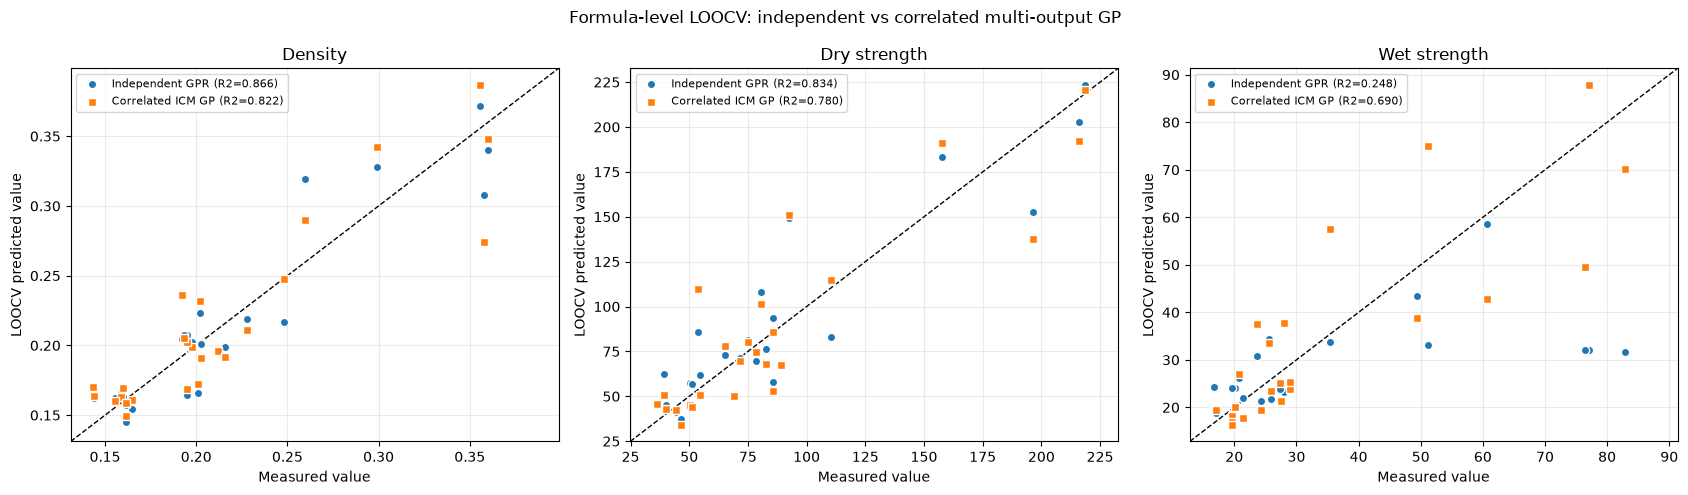

In [5]:
# Compare formula-level LOOCV predictions for each output.
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

plot_target_labels = {
    "Avg_Density_g_cm3": "Density",
    "Dry Strength Mean": "Dry strength",
    "Wet Strength Mean": "Wet strength",
}
fig, axes = plt.subplots(1, len(target_cols), figsize=(17, 5), squeeze=False)

for target_index, target in enumerate(target_cols):
    axis = axes[0, target_index]
    actual = Y[:, target_index]
    independent_prediction = independent_oof_predictions[:, target_index]
    correlated_prediction = correlated_oof_predictions[:, target_index]
    lower = min(actual.min(), independent_prediction.min(), correlated_prediction.min())
    upper = max(actual.max(), independent_prediction.max(), correlated_prediction.max())
    padding = (upper - lower) * 0.05 or 1.0
    limits = (lower - padding, upper + padding)

    axis.scatter(
        actual,
        independent_prediction,
        color="tab:blue",
        edgecolor="white",
        label=f"Independent GPR (R2={r2_score(actual, independent_prediction):.3f})",
        zorder=3,
    )
    axis.scatter(
        actual,
        correlated_prediction,
        color="tab:orange",
        marker="s",
        edgecolor="white",
        label=f"Correlated ICM GP (R2={r2_score(actual, correlated_prediction):.3f})",
        zorder=4,
    )
    axis.plot(limits, limits, linestyle="--", color="black", linewidth=1)
    axis.set_xlim(limits)
    axis.set_ylim(limits)
    axis.set_title(plot_target_labels[target])
    axis.set_xlabel("Measured value")
    axis.set_ylabel("LOOCV predicted value")
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)

fig.suptitle("Formula-level LOOCV: independent vs correlated multi-output GP")
fig.tight_layout()
plt.show()